# Experiment C — public reproduction notebook

This notebook reproduces the released Experiment C summaries and the scientific content of Figure 8 from the files in this package.

The default path is intentionally quick. It loads the released complete summary for the primary Intel curve, then directly recomputes every Gulf primary case, Intel severities $f=1,2$, and all empirical unique-mask cases from the frozen geometries, allocations, and masks. Set `FULL_RECOMPUTE = True` below to recompute every primary severity from the released inputs. The original complete primary run took about 40 minutes in its recorded environment, so the full mode is optional.

The structural-rank and information calculations below follow the final C convention: rank uses the unweighted active factor stack; $\Phi\_S(\pi)$ uses the weighted active factor stack; finite-$p$ allocations are never thresholded; and unavailable mass is not renormalized.

In [1]:
from pathlib import Path
import math
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl

ROOT = Path.cwd()
DATA = ROOT / "data"
FIGURES = ROOT / "figures"
REPRODUCED = ROOT / "reproduced"
REPRODUCED.mkdir(exist_ok=True)

FULL_RECOMPUTE = False

print("Package root:", ROOT)
print("FULL_RECOMPUTE =", FULL_RECOMPUTE)


Package root: /home/pswati/Desktop/Dropbox/Research/Current Research (2026)/2026-Lewis/open_source_release/C
FULL_RECOMPUTE = False


## Load the released inputs

The C package includes the exact frozen B-derived geometry/design files needed here, the C-cleaned D-optimal endpoints, the frozen exchangeable and empirical mask banks, and compact released summaries. No separate B download is needed.

In [2]:
P_VALUES = np.array([2.2, 2.5, 3.0, 4.0, 6.0, 8.0, 12.0, 16.0, 24.0, 32.0, 49.0, 64.0])
EXPECTED_LABELS = np.array([
    "uniform",
    "lewis_p=2.2",
    "lewis_p=2.5",
    "lewis_p=3",
    "lewis_p=4",
    "lewis_p=6",
    "lewis_p=8",
    "lewis_p=12",
    "lewis_p=16",
    "lewis_p=24",
    "lewis_p=32",
    "lewis_p=49",
    "lewis_p=64",
    "D-opt",
])

def load_dataset(dataset):
    if dataset == "intel":
        proc_file = DATA / "B_intel_processed_input_frozen.npz"
        b_file = DATA / "B_final_intel_raw.npz"
        d_file = DATA / "C_intel_Dopt_cleaned_frozen.npz"
        mask_file = DATA / "C_intel_exchangeable_mask_bank_frozen.npz"
        emp_file = DATA / "C_intel_empirical_availability_frozen.npz"
        factor_key = "B_blocks"
        r = 30
    elif dataset == "gulf":
        proc_file = DATA / "B_gulf_processed_input_frozen.npz"
        b_file = DATA / "B_final_gulf_raw.npz"
        d_file = DATA / "C_gulf_Dopt_cleaned_frozen.npz"
        mask_file = DATA / "C_gulf_exchangeable_mask_bank_frozen.npz"
        emp_file = DATA / "C_gulf_empirical_availability_frozen.npz"
        factor_key = "A_blocks"
        r = 4
    else:
        raise ValueError(dataset)

    proc = np.load(proc_file, allow_pickle=False)
    b = np.load(b_file, allow_pickle=False)
    d = np.load(d_file, allow_pickle=False)
    masks = np.load(mask_file, allow_pickle=False)
    empirical = np.load(emp_file, allow_pickle=False)

    assert np.array_equal(np.asarray(b["p_grid"], float), P_VALUES)

    designs = np.vstack([
        np.asarray(b["uniform_allocation"], float)[None, :],
        np.asarray(b["allocations"], float),
        np.asarray(d["cleaned_allocation"], float)[None, :],
    ])

    assert designs.shape[0] == len(EXPECTED_LABELS)
    assert np.all(designs >= 0)
    assert np.allclose(designs.sum(axis=1), 1.0, rtol=0, atol=1e-12)
    assert np.all(designs[:-1] > 0.0)

    factors = np.asarray(proc[factor_key], float)
    c_blocks = np.asarray(proc["C_blocks"], float)
    reconstructed_c = np.einsum("kir,kis->krs", factors, factors)
    assert np.allclose(reconstructed_c, c_blocks, rtol=1e-12, atol=1e-12)

    return {
        "r": r,
        "factors": factors,
        "C_blocks": c_blocks,
        "designs": designs,
        "masks": masks,
        "empirical": empirical,
        "dopt": d,
        "b": b,
        "proc": proc,
    }

intel = load_dataset("intel")
gulf = load_dataset("gulf")

print("Intel factors:", intel["factors"].shape, "designs:", intel["designs"].shape)
print("Gulf factors:", gulf["factors"].shape, "designs:", gulf["designs"].shape)
print("All design simplex checks: PASS")
print("Factor-to-C_i checks: PASS")


Intel factors: (52, 3, 30) designs: (14, 52)
Gulf factors: (10, 2, 4) designs: (14, 10)
All design simplex checks: PASS
Factor-to-C_i checks: PASS


## Final C numerical convention

For a mask, bit $j=1$ means block $j$ is unavailable. A surviving block is active only when its frozen coefficient is strictly positive. Structural rank is computed from the unweighted active factors using the machine-scaled SVD threshold. If that rank is full, we compute $\Phi\_S(\pi)$ from the singular values of the weighted active stack. No ridge, clipping, pseudodeterminant, or post-unavailability renormalization is used.

In [3]:
class WeightedSVDGuardrailError(RuntimeError):
    pass

def failed_code_to_mask(code, k):
    code = int(code)
    if code < 0 or code >= (1 << k):
        raise ValueError("Invalid failure code.")
    return np.array([bool((code >> j) & 1) for j in range(k)], dtype=bool)

def svd_rank_threshold(singular_values, n_rows, n_cols):
    s = np.asarray(singular_values, dtype=float)
    if len(s) == 0:
        return 0.0
    return np.finfo(float).eps * max(int(n_rows), int(n_cols)) * float(np.max(s))

def structural_rank_from_stack(stack, r):
    A = np.asarray(stack, dtype=float)
    if A.shape[0] == 0:
        return 0
    s = np.linalg.svd(A, compute_uv=False)
    tau = svd_rank_threshold(s, A.shape[0], A.shape[1])
    return int(np.sum(s > tau))

def evaluate_one_design(factors, allocation, failed_code, r):
    k = factors.shape[0]
    failed = failed_code_to_mask(failed_code, k)
    active = (~failed) & (allocation > 0.0)
    idx = np.flatnonzero(active)

    if len(idx) == 0:
        return 0.0, True

    active_factors = factors[idx]
    unweighted = active_factors.reshape(-1, r)
    if structural_rank_from_stack(unweighted, r) < r:
        return 0.0, True

    weighted = (
        np.sqrt(allocation[idx])[:, None, None] * active_factors
    ).reshape(-1, r)

    s = np.linalg.svd(weighted, compute_uv=False)[:r]
    if len(s) < r or np.any(~np.isfinite(s)) or np.any(s <= 0.0):
        raise WeightedSVDGuardrailError("Unusable weighted singular values.")

    log_phi = (2.0 / r) * np.sum(np.log(s))
    phi = float(np.exp(log_phi))
    if not np.isfinite(phi) or phi <= 0.0:
        raise WeightedSVDGuardrailError("Invalid/underflowed Phi.")

    return phi, False

def evaluate_code_all_designs(factors, designs, failed_code, r):
    # Uniform + finite-p designs have common full support.
    k = factors.shape[0]
    failed = failed_code_to_mask(failed_code, k)
    surviving_idx = np.flatnonzero(~failed)

    phi = np.zeros(designs.shape[0], dtype=float)
    rankloss = np.ones(designs.shape[0], dtype=bool)

    if len(surviving_idx) > 0:
        active_factors = factors[surviving_idx]
        unweighted = active_factors.reshape(-1, r)

        if structural_rank_from_stack(unweighted, r) == r:
            weights = designs[:-1, surviving_idx]
            weighted_stacks = (
                np.sqrt(weights)[:, :, None, None]
                * active_factors[None, :, :, :]
            ).reshape(designs.shape[0] - 1, -1, r)

            s = np.linalg.svd(weighted_stacks, compute_uv=False)[:, :r]
            if np.any(~np.isfinite(s)) or np.any(s <= 0.0):
                raise WeightedSVDGuardrailError("Unusable batched weighted singular values.")

            phi[:-1] = np.exp((2.0 / r) * np.sum(np.log(s), axis=1))
            rankloss[:-1] = False

    # Cleaned D-opt has exact zeros, so support must be handled separately.
    phi[-1], rankloss[-1] = evaluate_one_design(
        factors, designs[-1], failed_code, r
    )

    return phi, rankloss

print("Numerical functions loaded.")


Numerical functions loaded.


## Check the frozen mask banks

Intel exhaustively enumerates $f=1,2,3$ and stores 25,000 masks for every $f=4,\ldots,42$. Gulf exhaustively enumerates all masks for $f=1,\ldots,8$.

In [4]:
def check_mask_bank(dataset, obj, k, expected_f):
    bank = obj["masks"]
    f_values = np.asarray(bank["f_values"], int)
    counts = np.asarray(bank["counts"], int)
    modes = np.asarray(bank["sampling_mode"])
    assert np.array_equal(f_values, np.asarray(expected_f, int))

    for f, count in zip(f_values, counts):
        codes = np.asarray(bank[f"failed_codes_f{int(f):02d}"], dtype=np.uint64)
        assert len(codes) == count
        assert len(np.unique(codes)) == count
        # Check exact severity in every saved code.
        bitcounts = np.fromiter((bin(int(x)).count("1") for x in codes), dtype=np.int16, count=len(codes))
        assert np.all(bitcounts == f)

    print(dataset, "mask counts total =", int(counts.sum()))
    return pd.DataFrame({"f": f_values, "count": counts, "sampling_mode": modes})

intel_mask_info = check_mask_bank("Intel", intel, 52, range(1, 43))
gulf_mask_info = check_mask_bank("Gulf", gulf, 10, range(1, 9))

assert np.array_equal(intel_mask_info["count"].to_numpy()[:3], [52, 1326, 22100])
assert np.all(intel_mask_info["count"].to_numpy()[3:] == 25000)
assert np.array_equal(gulf_mask_info["count"].to_numpy(), [10,45,120,210,252,210,120,45])

print("Mask-bank structure: PASS")


Intel mask counts total = 998478
Gulf mask counts total = 1012
Mask-bank structure: PASS


## Direct primary recomputation checks

The default run recomputes all eight Gulf severity classes and the first two Intel classes directly from the released factors, designs, and masks. The complete Intel primary curves are then read from the released summary. This keeps the default notebook fast while still exercising the final rank and $\Phi\_S(\pi)$ logic on real masks.

In [5]:
released = pd.read_csv(DATA / "C_exchangeable_summary.csv")

def summary_matrix(dataset, field):
    sub = released[released["dataset"] == dataset].copy()
    fvals = np.sort(sub["f"].unique())
    mat = np.vstack([
        sub[sub["f"] == f].set_index("design_label").loc[EXPECTED_LABELS, field].to_numpy(float)
        for f in fvals
    ])
    return fvals, mat

intel_f_released, intel_mu_released = summary_matrix("intel", "mu_f")
_, intel_rho_released = summary_matrix("intel", "rho_f")
gulf_f_released, gulf_mu_released = summary_matrix("gulf", "mu_f")
_, gulf_rho_released = summary_matrix("gulf", "rho_f")

assert np.array_equal(intel_f_released, np.arange(1,43))
assert np.array_equal(gulf_f_released, np.arange(1,9))

def recompute_severities(obj, severities):
    mus, rhos = [], []
    for f in severities:
        codes = np.asarray(obj["masks"][f"failed_codes_f{int(f):02d}"], dtype=np.uint64)
        phi_rows = np.empty((len(codes), len(EXPECTED_LABELS)), dtype=float)
        loss_rows = np.empty((len(codes), len(EXPECTED_LABELS)), dtype=bool)
        for t, code in enumerate(codes):
            phi_rows[t], loss_rows[t] = evaluate_code_all_designs(
                obj["factors"], obj["designs"], code, obj["r"]
            )
        mus.append(phi_rows.mean(axis=0))
        rhos.append(loss_rows.mean(axis=0))
    return np.vstack(mus), np.vstack(rhos)

t0 = time.time()
gulf_mu_check, gulf_rho_check = recompute_severities(gulf, range(1,9))
intel_mu_check, intel_rho_check = recompute_severities(intel, [1,2])
elapsed = time.time() - t0

assert np.allclose(gulf_mu_check, gulf_mu_released, rtol=1e-12, atol=1e-14)
assert np.allclose(gulf_rho_check, gulf_rho_released, rtol=0, atol=1e-15)
assert np.allclose(intel_mu_check, intel_mu_released[:2], rtol=1e-12, atol=1e-14)
assert np.allclose(intel_rho_check, intel_rho_released[:2], rtol=0, atol=1e-15)

print(f"Direct primary checks: PASS ({elapsed:.2f} s)")
print("  Gulf: all f=1,...,8 recomputed")
print("  Intel: f=1,2 recomputed")


Direct primary checks: PASS (4.74 s)
  Gulf: all f=1,...,8 recomputed
  Intel: f=1,2 recomputed


## Recompute the secondary empirical comparison

We reconstruct the eligible empirical mask frequencies from the frozen regular-grid mask files, evaluate each distinct eligible mask once, and frequency-weight the result. This reproduces the complete secondary empirical comparison.

In [6]:
emp_released = pd.read_csv(DATA / "C_empirical_summary.csv")
emp_raw = np.load(DATA / "C_final_empirical_raw.npz", allow_pickle=False)

def recompute_empirical(dataset, obj, fmax):
    e = obj["empirical"]
    codes = np.asarray(e["failed_codes"], dtype=np.uint64)
    counts = np.asarray(e["failed_counts"], dtype=int)
    eligible = np.asarray(e["eligible_1_to_fmax"], dtype=bool)

    assert np.array_equal(eligible, (counts >= 1) & (counts <= fmax))

    unique_codes, freq = np.unique(codes[eligible], return_counts=True)

    # The small released empirical raw file is retained as a convenient
    # cross-check of the exact unique-mask representation used in the final run.
    stored_codes = np.asarray(emp_raw[f"{dataset}_unique_codes"], dtype=np.uint64)
    stored_freq = np.asarray(emp_raw[f"{dataset}_frequency"], dtype=int)
    assert np.array_equal(unique_codes, stored_codes)
    assert np.array_equal(freq, stored_freq)

    phi = np.empty((len(unique_codes), len(EXPECTED_LABELS)), float)
    loss = np.empty((len(unique_codes), len(EXPECTED_LABELS)), bool)
    for i, code in enumerate(unique_codes):
        phi[i], loss[i] = evaluate_code_all_designs(
            obj["factors"], obj["designs"], code, obj["r"]
        )

    weights = freq.astype(float)
    mu = (weights[:,None] * phi).sum(axis=0) / weights.sum()
    rho = (weights[:,None] * loss.astype(float)).sum(axis=0) / weights.sum()

    return unique_codes, freq, mu, rho

for dataset, obj, fmax in [("intel", intel, 42), ("gulf", gulf, 8)]:
    codes, freq, mu, rho = recompute_empirical(dataset, obj, fmax)
    sub = emp_released[emp_released["dataset"] == dataset].set_index("design_label").loc[EXPECTED_LABELS]
    assert np.allclose(mu, sub["mu_emp"].to_numpy(float), rtol=1e-12, atol=1e-14)
    assert np.allclose(rho, sub["rho_emp"].to_numpy(float), rtol=0, atol=1e-15)
    print(dataset, "empirical unique masks =", len(codes), "eligible anchors =", int(freq.sum()))

print("Empirical recomputation: PASS")


intel empirical unique masks = 384 eligible anchors = 2361
gulf empirical unique masks = 192 eligible anchors = 51235
Empirical recomputation: PASS


## Reproduce Figure 8

The released PDF in `figures/` is the exact retained paper figure. The cell below redraws the same scientific data and styling from `data/C_exchangeable_summary.csv` and writes a separate reproduced copy without modifying the released figure.

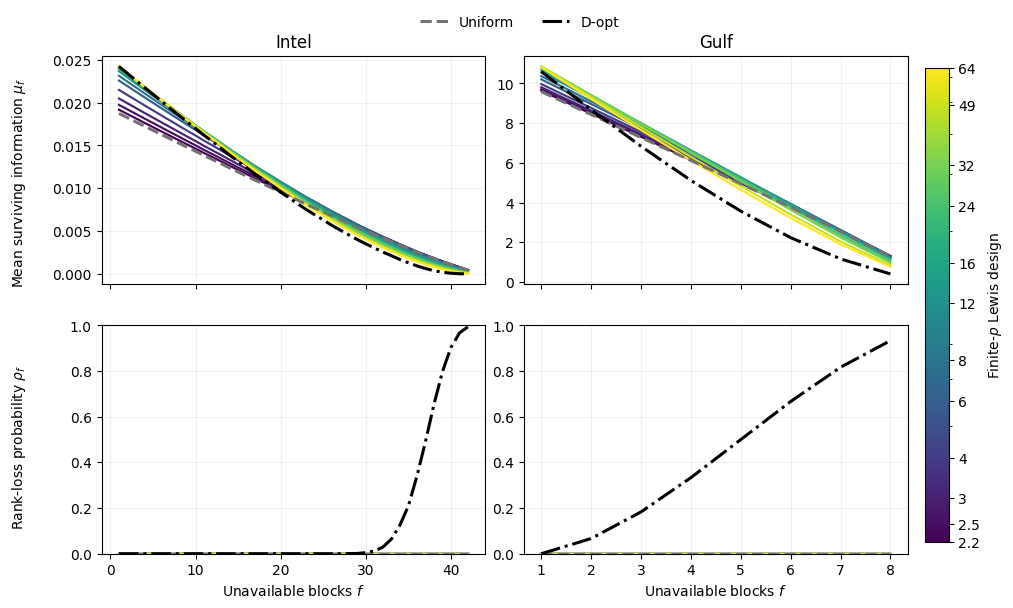

Reproduced figure:
  /home/pswati/Desktop/Dropbox/Research/Current Research (2026)/2026-Lewis/open_source_release/C/reproduced/C_exchangeable_mu_rho_combined_balanced_reproduced.pdf
  /home/pswati/Desktop/Dropbox/Research/Current Research (2026)/2026-Lewis/open_source_release/C/reproduced/C_exchangeable_mu_rho_combined_balanced_reproduced.png


In [7]:
cmap = mpl.colormaps["viridis"]
norm = mpl.colors.LogNorm(vmin=P_VALUES.min(), vmax=P_VALUES.max())

def draw_panel(ax, f_values, values):
    ax.plot(f_values, values[:,0], linestyle="--", linewidth=2.2, color="0.45", zorder=3)
    for j, p in zip(range(1,13), P_VALUES):
        ax.plot(f_values, values[:,j], linewidth=1.55, color=cmap(norm(p)), zorder=2)
    ax.plot(f_values, values[:,13], linestyle="-.", linewidth=2.2, color="black", zorder=3)
    ax.grid(alpha=0.18)

cfg = {
    "fig_w": 11.0, "fig_h": 6.3,
    "left": 0.11, "right": 0.88, "top": 0.90, "bottom": 0.11,
    "wspace": 0.10, "hspace": 0.18,
    "rowlabel_x": 0.035, "top_rowlabel_y": 0.70, "bot_rowlabel_y": 0.28,
    "cbar_fraction": 0.028, "cbar_pad": 0.02,
}

fig, axes = plt.subplots(2, 2, figsize=(cfg["fig_w"], cfg["fig_h"]), sharex="col")
fig.subplots_adjust(left=cfg["left"], right=cfg["right"], top=cfg["top"], bottom=cfg["bottom"],
                    wspace=cfg["wspace"], hspace=cfg["hspace"])

draw_panel(axes[0,0], intel_f_released, intel_mu_released)
draw_panel(axes[0,1], gulf_f_released, gulf_mu_released)
axes[0,0].set_title("Intel")
axes[0,1].set_title("Gulf")

draw_panel(axes[1,0], intel_f_released, intel_rho_released)
draw_panel(axes[1,1], gulf_f_released, gulf_rho_released)
axes[1,0].set_ylim(0.0, 1.0)
axes[1,1].set_ylim(0.0, 1.0)
axes[1,0].set_xlabel(r"Unavailable blocks $f$")
axes[1,1].set_xlabel(r"Unavailable blocks $f$")

fig.text(cfg["rowlabel_x"], cfg["top_rowlabel_y"],
         r"Mean surviving information $\mu_f$",
         rotation=90, va="center", ha="center")
fig.text(cfg["rowlabel_x"], cfg["bot_rowlabel_y"],
         r"Rank-loss probability $\rho_f$",
         rotation=90, va="center", ha="center")

endpoint_handles = [
    mpl.lines.Line2D([], [], linestyle="--", linewidth=2.2, color="0.45", label="Uniform"),
    mpl.lines.Line2D([], [], linestyle="-.", linewidth=2.2, color="black", label="D-opt"),
]
fig.legend(handles=endpoint_handles, loc="upper center", bbox_to_anchor=(0.49, 0.985),
           ncol=2, frameon=False)

sm = mpl.cm.ScalarMappable(norm=norm, cmap=cmap)
sm.set_array([])
cbar = fig.colorbar(sm, ax=axes, location="right",
                    fraction=cfg["cbar_fraction"], pad=cfg["cbar_pad"])
cbar.set_label(r"Finite-$p$ Lewis design")
cbar.set_ticks(P_VALUES)
cbar.set_ticklabels(["2.2","2.5","3","4","6","8","12","16","24","32","49","64"])

out_pdf = REPRODUCED / "C_exchangeable_mu_rho_combined_balanced_reproduced.pdf"
out_png = REPRODUCED / "C_exchangeable_mu_rho_combined_balanced_reproduced.png"
fig.savefig(out_pdf, format="pdf", bbox_inches="tight")
fig.savefig(out_png, format="png", dpi=180, bbox_inches="tight")
plt.show()

print("Reproduced figure:")
print(" ", out_pdf)
print(" ", out_png)


## Compact result check

The table below is descriptive. For Intel, the broad migration is stable, but individual sampled transition points should not be read as population-certified exact boundaries.

In [8]:
def finite_p_winner_ranges(dataset):
    sub = released[(released["dataset"] == dataset) & (released["design_type"] == "lewis")].copy()
    rows = []
    for f in sorted(sub["f"].unique()):
        s = sub[sub["f"] == f]
        j = s["mu_f"].idxmax()
        rows.append((int(f), s.loc[j, "design_label"], float(s.loc[j, "mu_f"])))
    return pd.DataFrame(rows, columns=["f","winning_finite_p","mu_f"])

print("Intel first/last finite-p winners:")
intel_w = finite_p_winner_ranges("intel")
display(intel_w.head(5))
display(intel_w.tail(5))

print("Gulf finite-p winners:")
display(finite_p_winner_ranges("gulf"))

print("Empirical best finite-p design:")
for dataset in ["intel","gulf"]:
    s = emp_released[(emp_released["dataset"] == dataset) & (emp_released["design_type"] == "lewis")]
    j = s["mu_emp"].idxmax()
    print(dataset, s.loc[j, "design_label"], s.loc[j, "mu_emp"])


Intel first/last finite-p winners:


,f,winning_finite_p,mu_f
0,1,lewis_p=64,0.024221
1,2,lewis_p=64,0.023427
2,3,lewis_p=64,0.022636
3,4,lewis_p=49,0.021842
4,5,lewis_p=32,0.021076


,f,winning_finite_p,mu_f
37,38,lewis_p=3,0.001838
38,39,lewis_p=2.5,0.001466
39,40,lewis_p=2.5,0.001121
40,41,lewis_p=2.5,0.000788
41,42,lewis_p=2.2,0.000459


Gulf finite-p winners:


,f,winning_finite_p,mu_f
0,1,lewis_p=32,10.861431
1,2,lewis_p=24,9.414221
2,3,lewis_p=24,8.006144
3,4,lewis_p=16,6.631769
4,5,lewis_p=12,5.272237
5,6,lewis_p=8,3.934544
6,7,lewis_p=6,2.617309
7,8,lewis_p=4,1.305506


Empirical best finite-p design:
intel lewis_p=49 0.0198751400788547
gulf lewis_p=24 9.500005042253678


## Optional complete primary recomputation

When `FULL_RECOMPUTE` is true, the following cell recomputes every released exchangeable-mask evaluation from the factors, designs, and masks, compares the resulting $\mu\_f$ and $\rho\_f$ arrays with the released summary, and writes a separate CSV under `reproduced/`. It never overwrites released data.

In [9]:
def full_recompute_dataset(dataset, obj, f_values):
    mu, rho = recompute_severities(obj, f_values)
    rows = []
    for ii, f in enumerate(f_values):
        for j, label in enumerate(EXPECTED_LABELS):
            rows.append({
                "dataset": dataset,
                "f": int(f),
                "design_label": label,
                "mu_f": float(mu[ii,j]),
                "rho_f": float(rho[ii,j]),
            })
    return pd.DataFrame(rows), mu, rho

if FULL_RECOMPUTE:
    start = time.time()

    intel_full_df, intel_mu_full, intel_rho_full = full_recompute_dataset(
        "intel", intel, range(1,43)
    )
    gulf_full_df, gulf_mu_full, gulf_rho_full = full_recompute_dataset(
        "gulf", gulf, range(1,9)
    )

    assert np.allclose(intel_mu_full, intel_mu_released, rtol=1e-12, atol=1e-14)
    assert np.allclose(intel_rho_full, intel_rho_released, rtol=0, atol=1e-15)
    assert np.allclose(gulf_mu_full, gulf_mu_released, rtol=1e-12, atol=1e-14)
    assert np.allclose(gulf_rho_full, gulf_rho_released, rtol=0, atol=1e-15)

    pd.concat([intel_full_df, gulf_full_df], ignore_index=True).to_csv(
        REPRODUCED / "C_exchangeable_summary_full_recomputed.csv", index=False
    )

    print(f"FULL_RECOMPUTE PASS in {time.time()-start:.1f} seconds")
else:
    print("FULL_RECOMPUTE is False; complete primary rerun skipped.")


FULL_RECOMPUTE is False; complete primary rerun skipped.


## Validation summary

A successful default run establishes that the released geometries and design allocations are internally consistent, the frozen mask banks have the prescribed dimensions/severities, the final C rank/$\Phi$ logic reproduces all Gulf primary summaries and the first two Intel primary summaries, the full empirical comparison reproduces from the frozen empirical masks, and the released primary summary redraws Figure 8.